P1 - IDIG4120 

Group members: Filza Akhlaq and Akanksha More

Submitted to: Steven Yves Le Moan

This notebook is divided in eight main sections as per the requirements of P1. 

#  1. Format, array shape, data type, units, range and byte size.

In [1]:
# setting up the root path
rdir ="./final_dataset"

In [2]:
# importing libraries
import os
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
import random

In [3]:
dataset_folder = Path("./mvtec_dataset")

## Loading and Exploring the Dataset

In [4]:
# creating a dictionary of images from the dataset and append the info such as
# filetype, shape, image size, datatype to each image
data_dict = {}

for objecttype in os.listdir(rdir):
    object_path = Path(rdir) / objecttype

    # Skip files which are not directories
    if not object_path.is_dir():
        continue

    object_dir = object_path / 'train'
    print(objecttype)

    for imgpath in object_dir.iterdir():
        if not imgpath.is_file():
            continue

        if objecttype not in data_dict:
            data_dict[objecttype] = []

        img = Image.open(imgpath)
        img_np = np.array(img)

        data_dict[objecttype].append((
            imgpath,
            imgpath.suffix,
            img_np.shape,
            imgpath.stat().st_size,
            img_np.dtype
        ))


transistor
capsule
metal_nut
pill
hazelnut


Displaying what is saved inside the data_dict as a pandas data frame; showing one instance from each class


In [5]:
rows = []

for objecttype, images in data_dict.items():
    if images:  # Make sure the class is not empty
        img = images[0]

        rows.append({
            "Class": objecttype,
            "Image": img[0].name,
            "File Type": img[1],
            "Shape": img[2],
            "Size (bytes)": img[3],
            "Data Type": img[4]
        })

df = pd.DataFrame(rows)

df

,Class,Image,File Type,Shape,Size (bytes),Data Type
0,transistor,176.png,.png,"(1024, 1024, 3)",1266924,uint8
1,capsule,176.png,.png,"(1000, 1000, 3)",1160668,uint8
2,metal_nut,176.png,.png,"(700, 700, 3)",501203,uint8
3,pill,176.png,.png,"(800, 800, 3)",607536,uint8
4,hazelnut,176.png,.png,"(1024, 1024, 3)",1224153,uint8


### Getting Metrics

In [6]:
# metrics sets
image_suffix_set = set()
image_shape_set = set()
image_dtype_set = set()
image_size_set = set()

# set the metrics for each image
for objecttype in data_dict:
    for img in data_dict[objecttype]:
        image_suffix_set.add(img[1])
        image_shape_set.add(img[2])
        image_size_set.add(img[3])
        image_dtype_set.add(img[4])

# Print sets
print(f'Image suffix set: {image_suffix_set}')
print(f'Image shape set: {image_shape_set}')
print(f'Image size : Min: {np.min(list(image_size_set)) / (1024*1024)}  in MB Max: {np.max(list(image_size_set)) / (1024*1024)} in MB,\n\t Average: {np.mean(list(image_size_set)) / (1024*1024)} +- {np.std(list(image_size_set))/ (1024*1024)} in MB')
print(f'Image dtype set: {image_dtype_set}')
print(f'Range: {(x:=np.iinfo(np.uint8)).min} to {x.max}')

Image suffix set: {'.png'}
Image shape set: {(700, 700, 3), (1000, 1000, 3), (1024, 1024, 3), (800, 800, 3)}
Image size : Min: 0.4553661346435547  in MB Max: 1.256704330444336 in MB,
	 Average: 0.9105683288959866 +- 0.31096007805763176 in MB
Image dtype set: {dtype('uint8')}
Range: 0 to 255


## Display a Random Datapoint

We chose to use random images from our dataset to maintain validity of our code each time it is run.

In [7]:
# function to get a random image from the dataset
def get_one_random_image(data_dict, objecttype:str = None) -> Path:
    objtype = objecttype or random.choice(list(data_dict.keys()))
    return random.choice(data_dict[objtype])

In [8]:
# A function that displays images with different parameters such as axes, title, label
def display_image(img, cmap: str = None, title: str = None, 
                  axes: bool = True, figsize=(4, 4),
                  xlabel: str = None, ylabel: str = None, xticks: list = None, yticks: list = None, ax=None):
    
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
        
    ax.imshow(img, cmap=cmap)

    if title is not None:
        ax.set_title(title)

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    if not axes:
        ax.axis('off')
        
    if xticks is not None:
        ax.set_xticks(xticks)
        
    if yticks is not None:
        ax.set_yticks(yticks)
        
    return ax

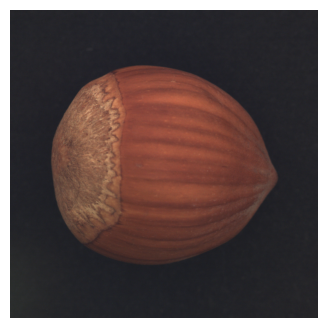

In [9]:
# display the random image
datapoint = get_one_random_image(data_dict)
imgpath = datapoint[0]
img = Image.open(imgpath)
display_image(img, axes = False)
plt.show()

# 2. Sampling rate or spacing. Say so where the concept does not apply, or is unknown.
Since our dataset is an image dataset, so sampling rate with respect to time does not apply on images, as they are in spatial domain, not in time domain. Several image dimensions are available such as 800 x 800 pixels, 1024 x 1024 pixels etc. However, the physical spacing between the pixels is unknown to us.

# 3. One time or spatial view and one frequency view, both with labelled axes.

## Spatial Domain View

Width of image:  700 
Height of image:  700


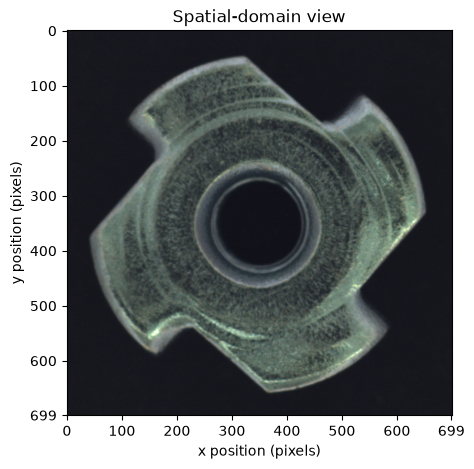

In [10]:
datapoint = get_one_random_image(data_dict)
imgpath = datapoint[0]
img_sd = Image.open(imgpath)

width, height = img_sd.size
print("Width of image: ", width,"\nHeight of image: ", height)

display_image(img_sd, title ="Spatial-domain view", xlabel = "x position (pixels)", ylabel ="y position (pixels)", figsize=(5, 5), xticks = list(range(0, width, 100)) + [width - 1], yticks = list(range(0, height, 100)) + [height - 1])
plt.show()

## Frequency Domain View

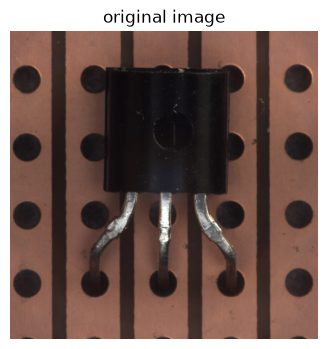


Image shape : (1024, 1024, 3) 



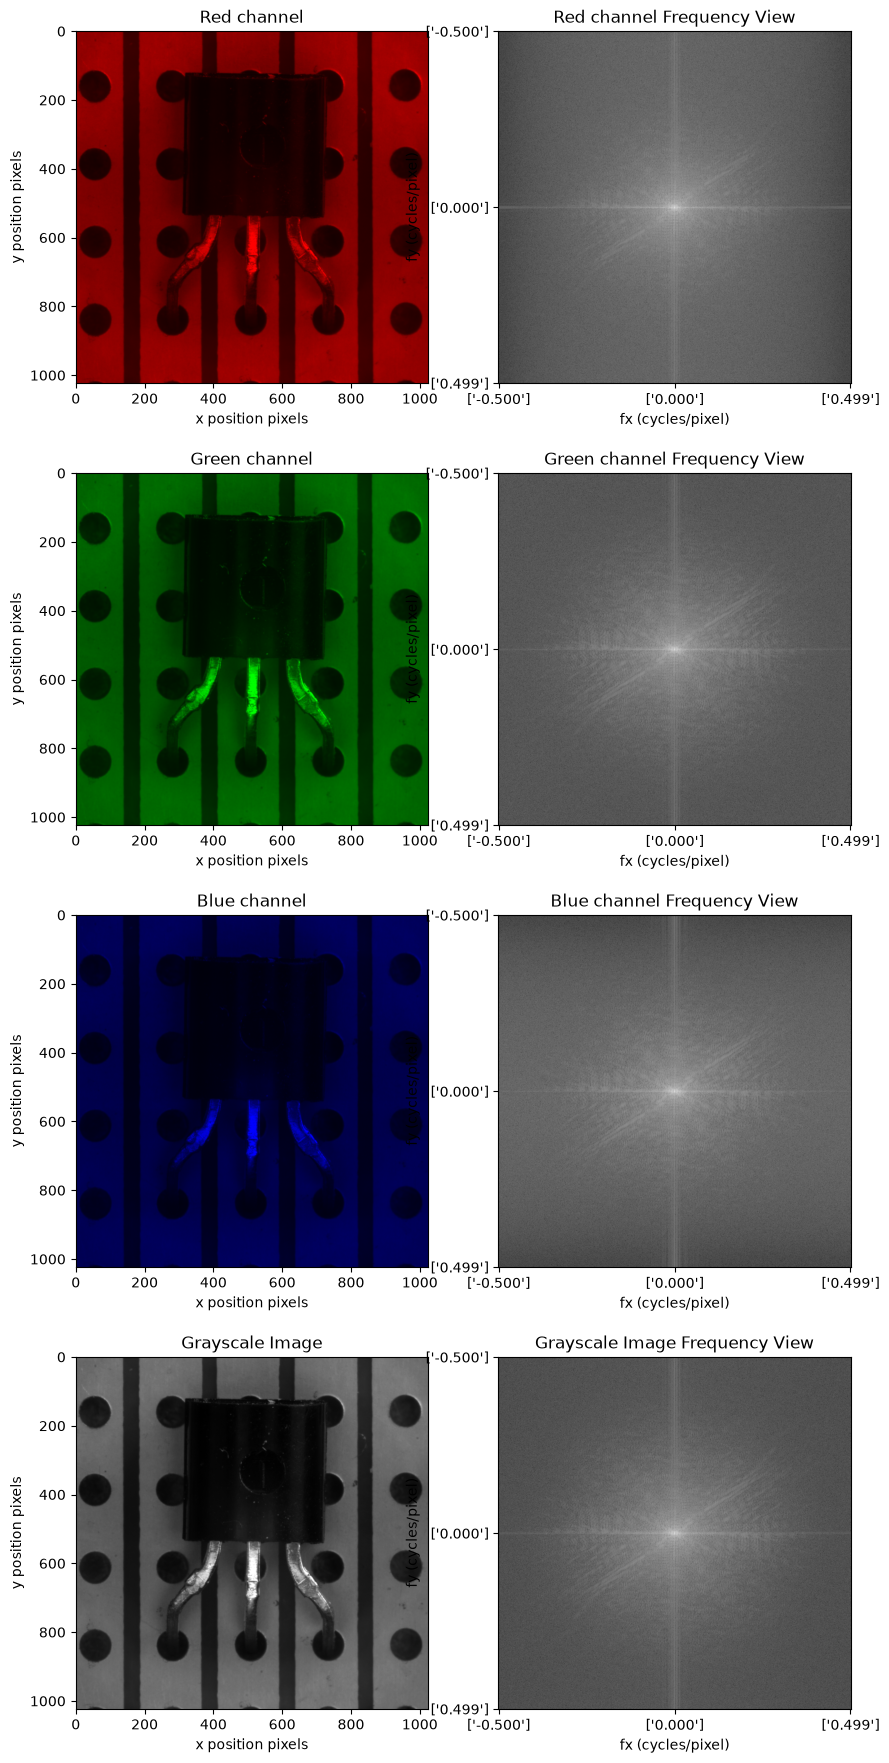

In [11]:
#datapoint = get_one_random_image(data_dict)
imgpath = dataset_folder / "058_transistor.png"
img = Image.open(imgpath)
display_image(img, title = "original image", axes= False)
plt.show()

img_array = np.array(img)
img_grayscale_array = np.array(img.convert('L'))
print("\nImage shape :" , img_array.shape,"\n")


'''rgb image'''
#plot frequency view for each RGB channel
channels = ["Red", "Green", "Blue"]

figure, plot_axes = plt.subplots(4, 2, figsize = (10, 22))

for i in range(3):

    #forward fourier transform on the image
    ft = np.fft.fft2(img_array[:,:,i])

    #shift to recentre zero
    ft_shift = np.fft.fftshift(ft)

    #compute the magnitude
    magnitude = np.log1p(np.abs(ft_shift))

    dummy_image = np.zeros_like(img_array)
    dummy_image[:,:,i] = img_array[:,:,i]
    
    display_image(dummy_image, title = channels[i]+" channel", xlabel = "x position pixels", ylabel = "y position pixels", ax = plot_axes[i,0])
    
    display_image(magnitude, title = channels[i]+" channel Frequency View", cmap="grey", xlabel = "fx (cycles/pixel)", ylabel = "fy (cycles/pixel)", ax = plot_axes[i,1])

''' grayscale image'''
#forward fourier transform on the grayscale image
ft_grayscale = np.fft.fft2(img_grayscale_array)

#shift to recentre zero
ft_grayscale_shift = np.fft.fftshift(ft_grayscale)

#compute the magnitude of complex numbers
magnitude = np.log1p(np.abs(ft_grayscale_shift))

display_image(img_grayscale_array, title = "Grayscale Image", cmap="grey", xlabel = "x position pixels", ylabel = "y position pixels", ax = plot_axes[3,0])

display_image(magnitude, title = "Grayscale Image Frequency View", cmap="grey", xlabel = "fx (cycles/pixel)", ylabel = "fy (cycles/pixel)", ax = plot_axes[3,1])

height, width = img_array.shape[:2]

fx = np.fft.fftshift(np.fft.fftfreq(width))
fy = np.fft.fftshift(np.fft.fftfreq(height))

x_positions = [0, width // 2, width -1]
y_positions = [0, height // 2, height -1]

for ax in plot_axes[:,1]:
    ax.set_xticks(x_positions)
    ax.set_xticklabels([f"{fx[p]:.3f}"] for p in x_positions)
    ax.set_yticks(y_positions)
    ax.set_yticklabels([f"{fy[p]:.3f}"] for p in y_positions)

plt.show()

# 4. One transform or filtering experiment, with the prediction you made before running it.

For this part, a low-pass filter is chosen, which is simply computing the FFT of the image. We compute the three FFTs separately because the images are RGB, and we have 2D FT available. After computing these three separately, we will combine them into one image so we can have the FT of the RGB image.


### Inspecting the three RGB channels separately first

Shape: (800, 800, 3)
Data type: uint8


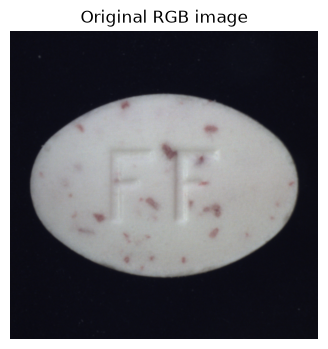

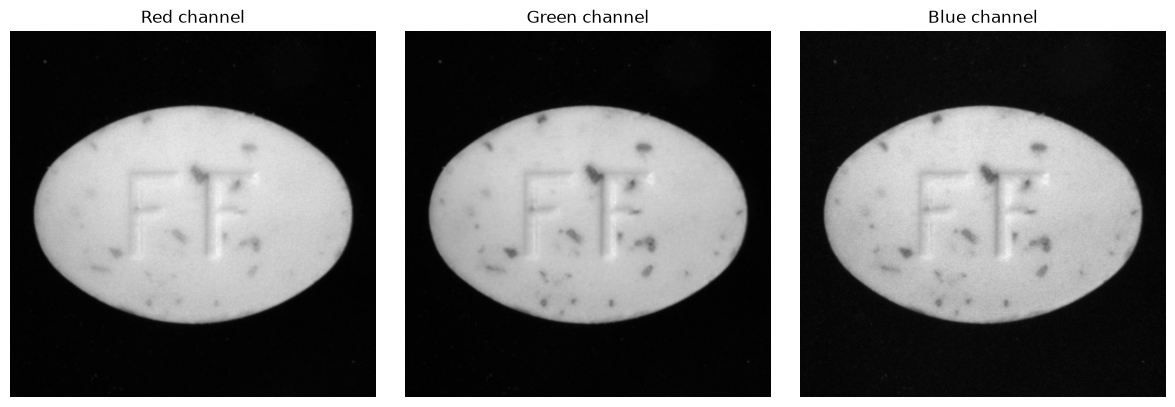

In [12]:
datapoint = get_one_random_image(data_dict)
imgpath = datapoint[0]
img = Image.open(imgpath)
img_array = np.array(img)

print("Shape:", img_array.shape)
print("Data type:", img_array.dtype)

display_image(img_array, title = "Original RGB image", axes = False)
plt.show()

R = img_array[:, :, 0]
G = img_array[:, :, 1]
B = img_array[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

display_image(R, title = "Red channel", cmap='gray', ax = axes[0], axes = False)
display_image(G, title = "Green channel", cmap='gray', ax = axes[1], axes = False)
display_image(B, title = "Blue channel", cmap='gray', ax = axes[2], axes = False)

plt.tight_layout()
plt.show()

The above images do not show RGB colours because they are showing colour intensity rather than the colour itself.

### Computing FFT of each channel separately 

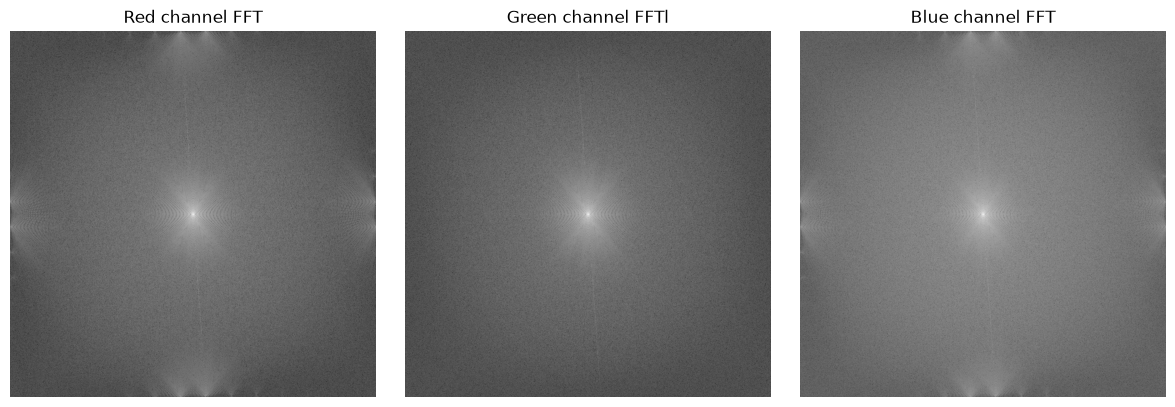

Low frequencies are moved to the center.


In [13]:
# fftshist is shifting low frequencies to the center
# fft2 computing the 2D fourier transform of RGB channels 
FR = np.fft.fftshift(np.fft.fft2(R))
FG = np.fft.fftshift(np.fft.fft2(G))
FB = np.fft.fftshift(np.fft.fft2(B))

mag_R = 20 * np.log10(np.abs(FR) + 1e-8)
mag_G = 20 * np.log10(np.abs(FG) + 1e-8)
mag_B = 20 * np.log10(np.abs(FB) + 1e-8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

display_image(mag_R, title = "Red channel FFT", cmap = "gray", ax = axes[0], axes = False)
display_image(mag_G, title = "Green channel FFTl", cmap = "gray", ax = axes[1], axes = False)
display_image(mag_B, title = "Blue channel FFT", cmap = "gray", ax = axes[2], axes = False)

plt.tight_layout()
plt.show()

print("Low frequencies are moved to the center.")

**Make a prediction before applying the filter**

Prediction: Applying a low-pass filter will remove high spatial frequencies and preserve low spatial frequencies. I therefore expect the image to become smoother and lose fine texture and sharp edge details. A smaller cutoff should produce stronger smoothing because fewer frequencies are retained.

### Creating a Low-pass mask

Here, we are creating a low-pass mask to later apply on all the RGB channels separately. For experimental purposes, we are choosing three different radii = [30, 80, 150].

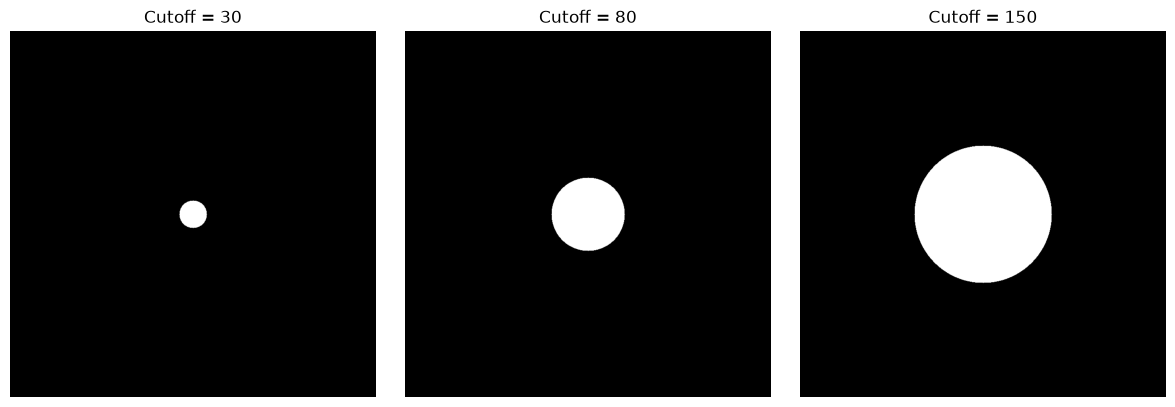

In [14]:
# For every position in the FFT, we are calculating how far it is from the centre. 
# Then keeping positions within 80 pixels of the centre.

rows, cols = R.shape

y, x = np.ogrid[:rows, :cols]

center_y = rows // 2
center_x = cols // 2

distance = np.sqrt((x - center_x)**2 + (y - center_y)**2) # distance formula 

# experimenting three different cut-offs
cutoffs = [30, 80, 150] # most, medium, and least blur

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, cutoff in zip(axes, cutoffs):
    mask = distance <= cutoff
    
    display_image(mask, title = f"Cutoff = {cutoff}", cmap = "gray", ax = ax, axes = False)

plt.tight_layout()
plt.show()

**Applying the three cut-offs to red channel:**

Applied low-pass filter with cutoff = 30
Applied low-pass filter with cutoff = 80
Applied low-pass filter with cutoff = 150

Created 3 filtered frequency-domain results.


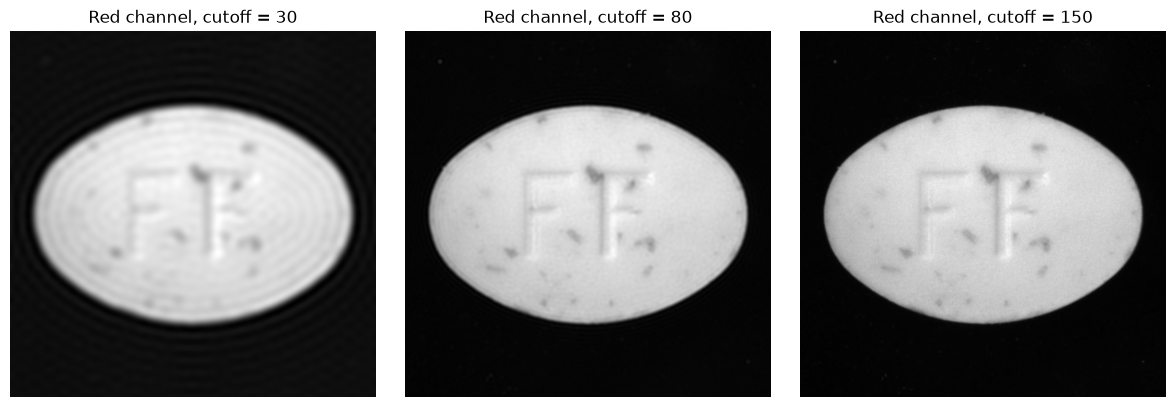

In [15]:
filtered_red = []

for cutoff in cutoffs:
    mask = distance <= cutoff
    FR_filtered = FR * mask
    filtered_red.append(FR_filtered)

    print(f"Applied low-pass filter with cutoff = {cutoff}")

print(f"\nCreated {len(filtered_red)} filtered frequency-domain results.")

red_results = []

for FR_filtered in filtered_red:
    # Undo the shift
    unshifted = np.fft.ifftshift(FR_filtered)

    # Convert frequency domain back to spatial domain
    red_img = np.fft.ifft2(unshifted)

    # Keep the real part
    red_img = np.real(red_img)

    red_results.append(red_img)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, cutoff, red_img in zip(axes, cutoffs, red_results):
    
    display_image(red_img, title = f"Red channel, cutoff = {cutoff}", cmap = "gray", ax = ax, axes = False)

plt.tight_layout()
plt.show()

**Applying the three cut-offs to green channel:**

Applied low-pass filter to Green channel with cutoff = 30
Applied low-pass filter to Green channel with cutoff = 80
Applied low-pass filter to Green channel with cutoff = 150

Created 3 filtered Green frequency-domain results.


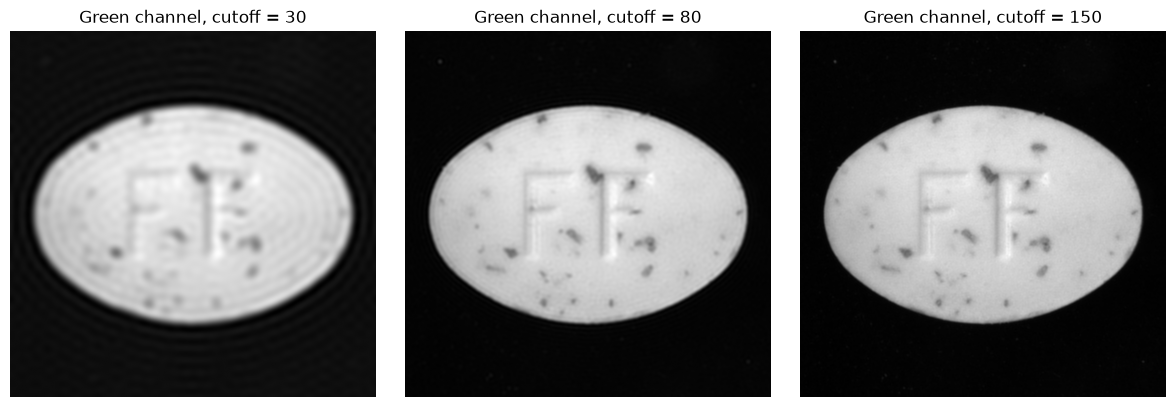

In [16]:
filtered_green = []

for cutoff in cutoffs:
    mask = distance <= cutoff
    FG_filtered = FG * mask
    filtered_green.append(FG_filtered)

    print(f"Applied low-pass filter to Green channel with cutoff = {cutoff}")

print(f"\nCreated {len(filtered_green)} filtered Green frequency-domain results.")

green_results = []

for FG_filtered in filtered_green:
    unshifted = np.fft.ifftshift(FG_filtered)

    green_img = np.fft.ifft2(unshifted)

    green_img = np.real(green_img)

    green_results.append(green_img)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, cutoff, green_img in zip(axes, cutoffs, green_results):
    
    display_image(green_img, title = f"Green channel, cutoff = {cutoff}", cmap = "gray", ax = ax, axes = False)

plt.tight_layout()
plt.show()

**Applying the three cut-offs to blue channel:**

Applied low-pass filter to Blue channel with cutoff = 30
Applied low-pass filter to Blue channel with cutoff = 80
Applied low-pass filter to Blue channel with cutoff = 150

Created 3 filtered Blue frequency-domain results.


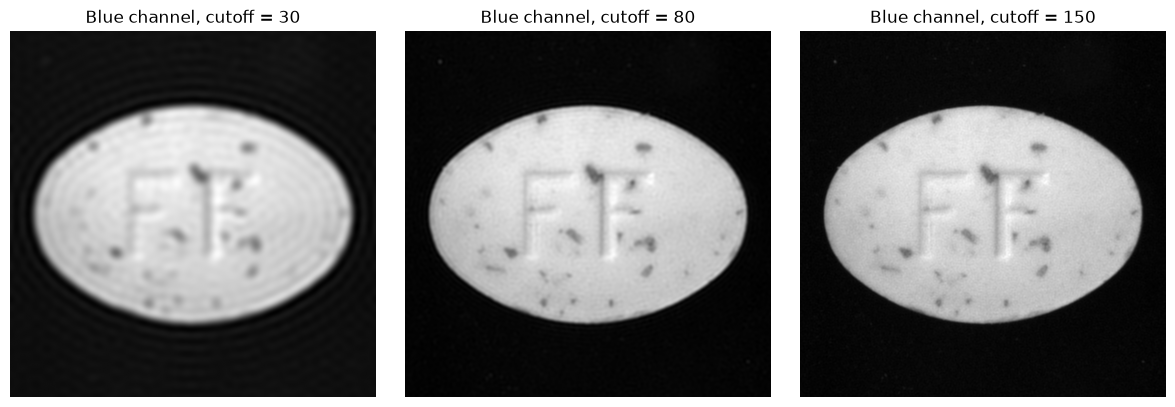

In [17]:
filtered_blue = []

for cutoff in cutoffs:
    mask = distance <= cutoff
    FB_filtered = FB * mask
    filtered_blue.append(FB_filtered)

    print(f"Applied low-pass filter to Blue channel with cutoff = {cutoff}")

print(f"\nCreated {len(filtered_blue)} filtered Blue frequency-domain results.")

blue_results = []

for FB_filtered in filtered_blue:
    unshifted = np.fft.ifftshift(FB_filtered)

    blue_img = np.fft.ifft2(unshifted)

    blue_img = np.real(blue_img)

    blue_results.append(blue_img)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, cutoff, blue_img in zip(axes, cutoffs, blue_results):
    
    display_image(blue_img, title = f"Blue channel, cutoff = {cutoff}", cmap = "gray", ax = ax, axes = False)

plt.tight_layout()
plt.show()

**Recombining the three channels to make the RGB image:**

Combined RGB image for cutoff = 30
Combined RGB image for cutoff = 80
Combined RGB image for cutoff = 150


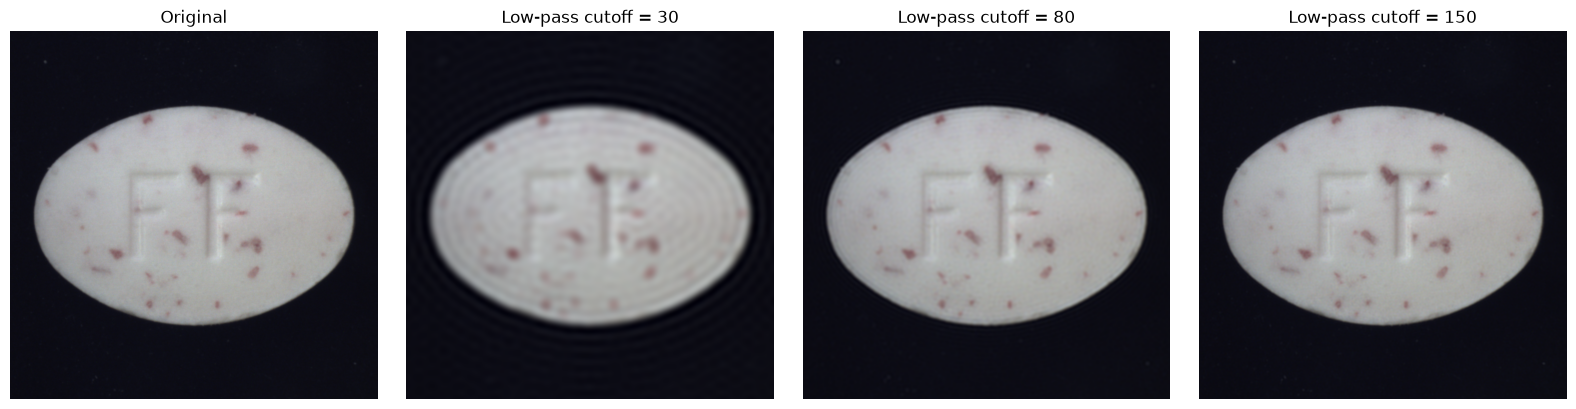

In [18]:
rgb_results = []

for i, cutoff in enumerate(cutoffs):
    rgb_img = np.stack([
        red_results[i],
        green_results[i],
        blue_results[i]
    ], axis=2)

    # Keep values in valid image range
    rgb_img = np.clip(rgb_img, 0, 255).astype(np.uint8)

    rgb_results.append(rgb_img)

    print(f"Combined RGB image for cutoff = {cutoff}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

display_image(img_array, title = "Original", axes = False, ax = axes[0])

# axes[0].imshow(img_array)
# axes[0].set_title("Original")
# axes[0].axis("off")

for ax, cutoff, rgb_img in zip(axes[1:], cutoffs, rgb_results):
    
    display_image(rgb_img, title = f"Low-pass cutoff = {cutoff}", axes = False, ax=ax)
    
plt.tight_layout()
plt.show()

# 5. One resampling or quantisation experiment that finds an artefact or a limitation.


4-bit:  MSE - 75.498 PSNR - 29.351
2-bit:  MSE - 1203.794 PSNR - 17.325
1-bit:  MSE - 4627.221 PSNR - 11.478


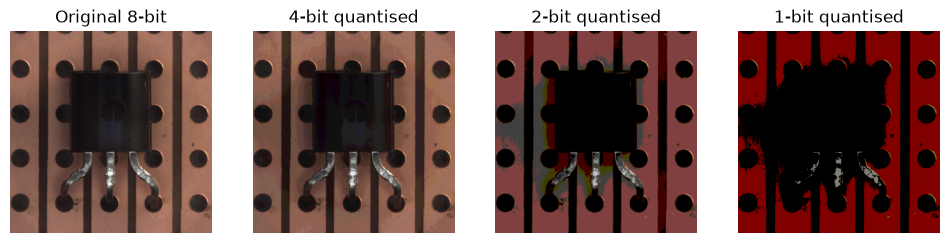

In [19]:
img_array = np.array(Image.open("./final_dataset/transistor/train/190.png"))

fig, axes = plt.subplots(1, 4, figsize=(12,8))

display_image(img_array, title = "Original 8-bit", axes = False, ax = axes[0] )

bits = [4,2,1]
mse = []
psnr = []

# 2 power - 4,2,1
for index,b in enumerate(bits):

    # quatise 8-bit image
    img_uint_b = img_array // 2**(8-b)

    # rescale image to 8-bit
    img_rescale = img_uint_b * 2**(8-b)

    # mean squared error
    difference = img_array.astype(np.float64) - img_rescale.astype(np.float64)
    mse.append(np.mean(difference**2))

    # peak signal to noise ratio
    psnr.append(10*np.log10(255**2 / mse[index]))

    print(f"{b}-bit:  MSE - {float(mse[index]):.3f} PSNR - {float(psnr[index]):.3f}")

    display_image(img_rescale, title = f"{b}-bit quantised", axes = False, ax = axes[index+1])

plt.show()

**Observation:**
Reducing the number of bits, takes the away the details of the image. The parts with gradients start looking like discrete blocks of colours. As we reduce the number of bits, details like shadows and textures are lost. Even though the 4-bit image still looks like a work around, 2-bits and 1-bit images still have a visible loss of information. Thus, if we are trying to improve storage efficieny by quantising the images, it comes at a tradeoff.

# 6. A reproducible loader, and the baseline representation P2 will be measured against.


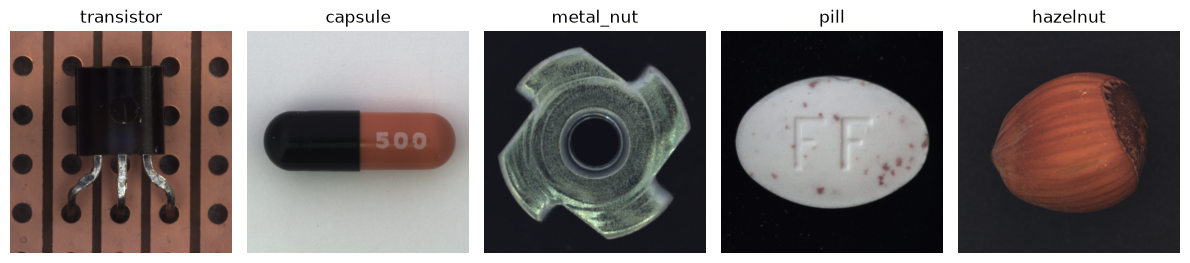

In [20]:
# Load a random image of each category: capsule, metal_nut, pill, transistor
fig, axes = plt.subplots(1, len(data_dict), figsize=(12, 3))

for ax, objecttype in zip(axes, data_dict):
    obj = get_one_random_image(data_dict, objecttype)
    imgpath = obj[0]

    img = Image.open(imgpath)
    
    display_image(img, title = objecttype, axes = False, ax = ax)

plt.tight_layout()
plt.show()

# 7. One Visual Informatics concern and one implementation, integrity or security concern that meet in this dataset. 

One visual informatics concern that can be observed in the dataset the significant loss of data such as texture, colour and details during the quantization process. These details can be particularly important because the dataset is used for defect anomaly identification, and loss of data can affect the detection. Lossy data can lead to inaedquate categorization of image which raises integrity concern. Since quantisation can lose important details, anomalies or defect detials may get lost and no defect may be identified which raises security concern. Thus the respresentation and quality of visual data can directly affect the reliability and integrity of the anomaly-detection process.

# 8. Who did what, and the generative-AI declaration. **

All the work was done while keeping each other regularly updated through meetings using an agile process, where both of us were constantly giving our suggestions to each other. We have shown the work division by referring to the respective section number as follows:

Akanksha: setting up the initial data loader, 1, 3 (frequency view), 5, 6, 7.

Filza: 1 (dataframe), 2, 3 (spatial view), 4, 6 (conceptualization), compiling the final code.

AI declaration: We used AI as a supporting tool to refer for code suggestions and improving code quality. Generative AI was not used to produce any results or data.